# Understanding neural networks through visual examples

**Author and maintainer: Sheima Alameeri, PhD**  
Applied Statistics and Research Methods | Colorado, USA

A visual introduction for readers who know basic regression and Python. We build intuition from a single neuron, then train small neural networks with PyTorch on newly generated synthetic data.

By the end, you will understand weights and biases, nonlinear activations, prediction before and after training, training versus validation error, and why fitting observations closely can hurt generalization.

All figures are generated by this notebook. This is an educational tutorial on established methods, separate from my dissertation implementation. References credit the mathematical background and software APIs.


## 1. Start with one neuron

A scalar-input neuron first forms $z=wx+b$, then applies an activation $a=\phi(z)$. The weight $w$ changes the slope of the pre-activation; the bias $b$ shifts it. The first graphs show the affine calculation before applying an activation.

In a network, each hidden unit combines the outputs from the preceding layer. Parameters are learned by minimizing a loss on training data. We use real-valued outputs throughout; this tutorial is about regression, not classification.


Python 3.12.14 | PyTorch 2.14.1+cpu | NumPy 2.3.5 | Matplotlib 3.10.8
CPU only; deterministic algorithms enabled; seed: 2026


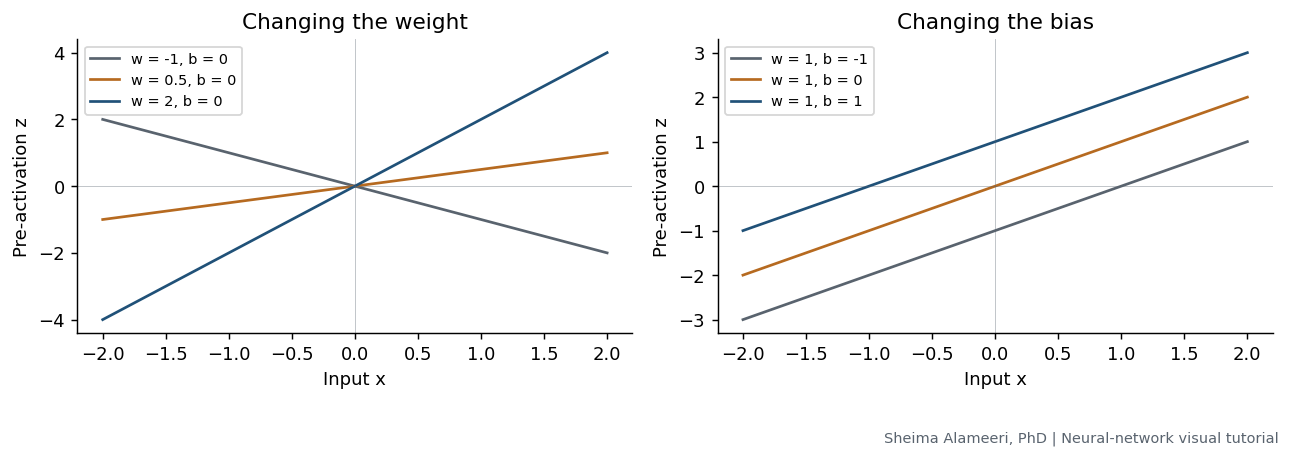

In [1]:
# Author and maintainer: Sheima Alameeri, PhD
from pathlib import Path
from copy import deepcopy
import platform
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyArrowPatch
import torch
from torch import nn

SEED = 2026
torch.manual_seed(SEED)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
ASSETS = Path('assets')
ASSETS.mkdir(exist_ok=True)
BLUE, ORANGE, GRAY = '#205178', '#b66a20', '#59636e'
plt.rcParams.update({'figure.dpi':120, 'font.size':10,
                     'axes.spines.top':False, 'axes.spines.right':False})

def save_figure(fig, filename):
    fig.text(0.99, 0.006, 'Sheima Alameeri, PhD | Neural-network visual tutorial',
             ha='right', va='bottom', fontsize=8, color=GRAY)
    fig.savefig(ASSETS / filename, dpi=160)
    plt.show()

def tensor(x):
    return torch.as_tensor(np.asarray(x), dtype=torch.float32).reshape(-1, 1)

print(f'Python {platform.python_version()} | PyTorch {torch.__version__} | '
      f'NumPy {np.__version__} | Matplotlib {matplotlib.__version__}')
print('CPU only; deterministic algorithms enabled; seed:', SEED)

x_line = np.linspace(-2, 2, 200)
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for w, color in zip([-1, 0.5, 2], [GRAY, ORANGE, BLUE]):
    axes[0].plot(x_line, w*x_line, color=color, label=f'w = {w}, b = 0')
for b, color in zip([-1, 0, 1], [GRAY, ORANGE, BLUE]):
    axes[1].plot(x_line, x_line+b, color=color, label=f'w = 1, b = {b}')
for ax, title in zip(axes, ['Changing the weight', 'Changing the bias']):
    ax.axhline(0, color=GRAY, lw=0.5, alpha=0.4)
    ax.axvline(0, color=GRAY, lw=0.5, alpha=0.4)
    ax.set(xlabel='Input x', ylabel='Pre-activation z', title=title)
    ax.legend(fontsize=8)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_figure(fig, 'weights-and-biases.png')


## 2. Why activation functions matter

An affine layer transforms its inputs linearly and adds a bias. Composing affine layers without nonlinear activations still yields an affine map. Nonlinear activations allow a network to represent nonlinear relationships.

These graphs compare identity, ReLU, tanh, and sigmoid. ReLU is $\max(0,z)$; tanh lies between -1 and 1; sigmoid is $1/(1+e^{-z})$ and lies between 0 and 1. The range of a hidden activation is not the range of the entire network when a separate linear output layer follows it.


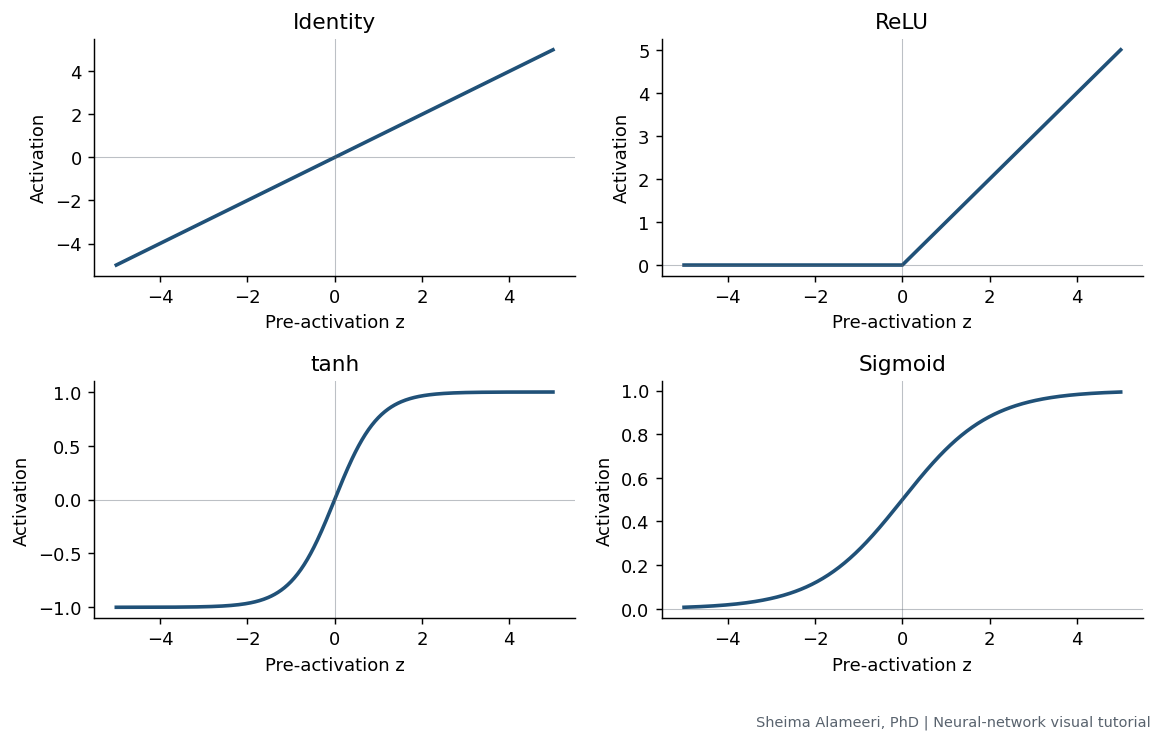

Activation definitions checked against PyTorch.


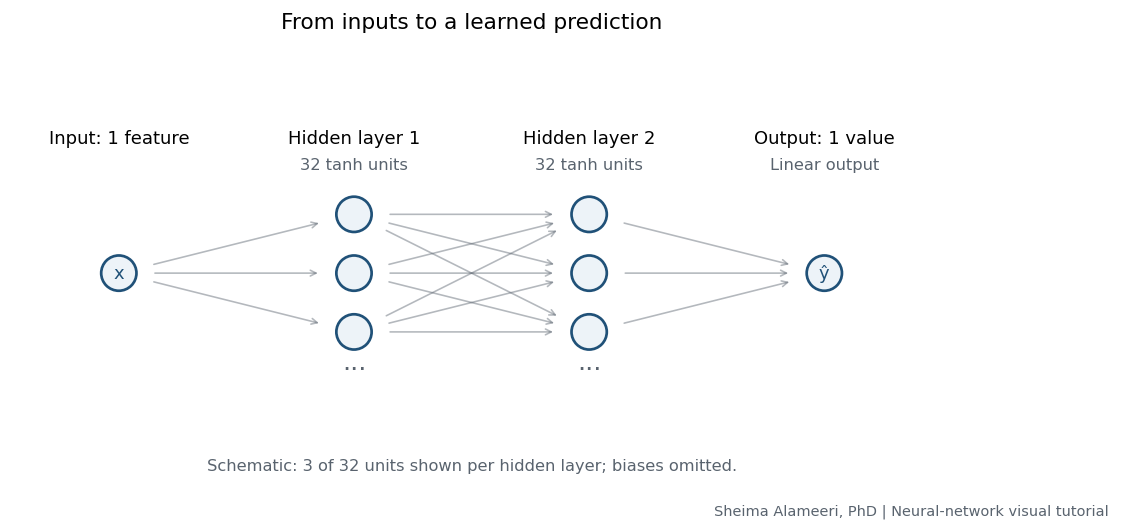

In [2]:
z = np.linspace(-5, 5, 401)
activation_functions = {
    'Identity': lambda a: a,
    'ReLU': lambda a: np.maximum(a, 0),
    'tanh': np.tanh,
    'Sigmoid': lambda a: 1/(1+np.exp(-a)),
}
fig, axes = plt.subplots(2, 2, figsize=(9, 5.7))
for ax, (name, function) in zip(axes.flat, activation_functions.items()):
    ax.plot(z, function(z), color=BLUE, lw=2)
    ax.axhline(0, color=GRAY, lw=0.6, alpha=0.4)
    ax.axvline(0, color=GRAY, lw=0.6, alpha=0.4)
    ax.set(xlabel='Pre-activation z', ylabel='Activation', title=name)
fig.tight_layout(rect=(0, 0.05, 1, 1))
save_figure(fig, 'activation-functions.png')

# Verify the plotted NumPy definitions against PyTorch.
zt = torch.tensor(z, dtype=torch.float64)
np.testing.assert_allclose(activation_functions['ReLU'](z), torch.relu(zt).numpy())
np.testing.assert_allclose(activation_functions['tanh'](z), torch.tanh(zt).numpy(), atol=1e-14)
np.testing.assert_allclose(activation_functions['Sigmoid'](z), torch.sigmoid(zt).numpy(), atol=1e-14)
print('Activation definitions checked against PyTorch.')

# A schematic of the model used in the next section.
fig, ax = plt.subplots(figsize=(10, 4.0))
layers = [[(0,0.5)], [(1,0.75),(1,0.5),(1,0.25)],
          [(2,0.75),(2,0.5),(2,0.25)], [(3,0.5)]]
for left, right in zip(layers[:-1], layers[1:]):
    for a in left:
        for b in right:
            ax.add_patch(FancyArrowPatch(a,b,arrowstyle='->',mutation_scale=8,
                                        shrinkA=20,shrinkB=20,lw=0.9,
                                        color=GRAY,alpha=0.45,zorder=1))
for layer in layers:
    for x,y in layer:
        ax.add_patch(Circle((x,y),0.075,facecolor='#edf3f8',edgecolor=BLUE,lw=1.5,zorder=2))
for x,label in enumerate(['Input: 1 feature','Hidden layer 1','Hidden layer 2','Output: 1 value']):
    ax.text(x,1.05,label,ha='center',fontsize=10)
ax.text(1,0.94,'32 tanh units',ha='center',fontsize=9,color=GRAY)
ax.text(2,0.94,'32 tanh units',ha='center',fontsize=9,color=GRAY)
ax.text(3,0.94,'Linear output',ha='center',fontsize=9,color=GRAY)
ax.text(1,0.09,'...',ha='center',fontsize=14,color=GRAY)
ax.text(2,0.09,'...',ha='center',fontsize=14,color=GRAY)
ax.text(0,0.5,'x',ha='center',va='center',color=BLUE,zorder=3)
ax.text(3,0.5,'ŷ',ha='center',va='center',fontsize=10,color=BLUE,zorder=3)
ax.set(xlim=(-0.45,3.45),ylim=(-0.1,1.2))
fig.suptitle('From inputs to a learned prediction',y=0.98,fontsize=12)
ax.set_aspect('equal')
ax.axis('off')
fig.text(0.5,0.10,'Schematic: 3 of 32 units shown per hidden layer; biases omitted.',
         ha='center',fontsize=9,color=GRAY)
fig.tight_layout(rect=(0,0.17,1,0.91))
save_figure(fig, 'network-architecture.png')


## 3. Train a small network

We generate a nonlinear regression signal on [-1, 1], then create separate training and validation observations. The validation data do not contribute gradients. We fix the training budget in advance for this first example.

Our network has architecture **1 → 32 → 32 → 1**, with tanh hidden activations and a linear output. The loss is mean squared error, $L=\frac{1}{n}\sum_i(\hat y_i-y_i)^2$. Adam updates the parameters using gradients calculated by automatic differentiation.

The training loop clears accumulated gradients, computes predictions and loss, calls `backward()`, and takes an optimizer step. Both plotted losses are measured after the same update and use the same MSE definition.


 Epoch  Training MSE  Validation MSE
     0        0.5302          0.5127
  1200        0.0172          0.0334


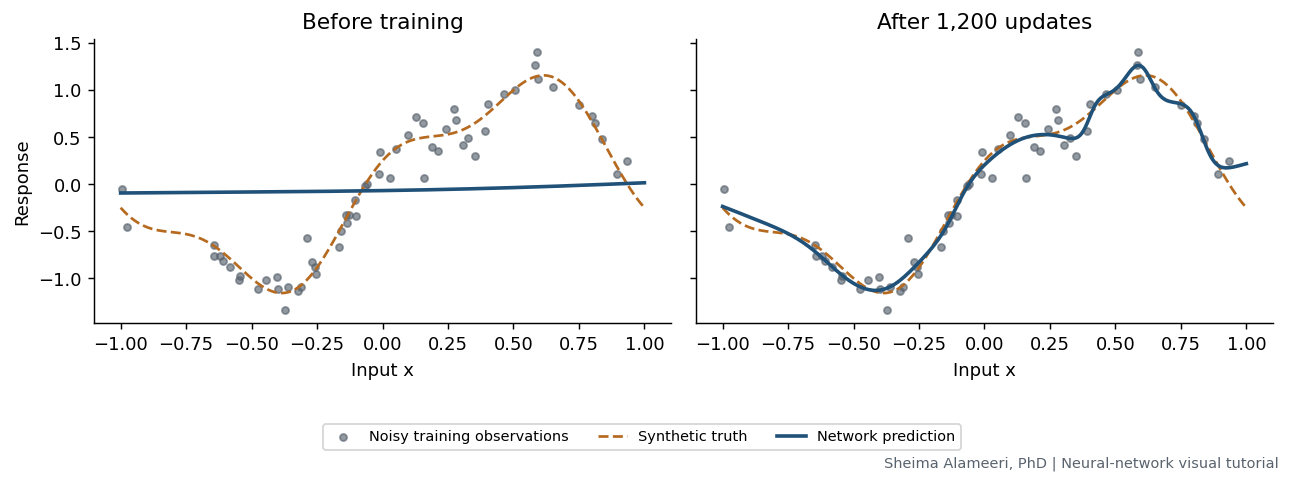

In [3]:
def true_function(x):
    x = np.asarray(x)
    return np.sin(np.pi*x) + 0.25*np.cos(3*np.pi*x)

def make_data(seed, n_train, n_valid, noise_std):
    rng = np.random.default_rng(seed)
    x_train = rng.uniform(-1, 1, n_train)
    x_valid = rng.uniform(-1, 1, n_valid)
    y_train = true_function(x_train) + rng.normal(0, noise_std, n_train)
    y_valid = true_function(x_valid) + rng.normal(0, noise_std, n_valid)
    return tensor(x_train), tensor(y_train), tensor(x_valid), tensor(y_valid)

def make_model(width, activation, seed):
    torch.manual_seed(seed)
    return nn.Sequential(nn.Linear(1, width), activation(),
                         nn.Linear(width, width), activation(), nn.Linear(width, 1))

def predict(model, x):
    model.eval()
    with torch.no_grad():
        return model(x).numpy().reshape(-1)

def train_model(model, x_train, y_train, x_valid, y_valid, epochs, lr):
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    mse = nn.MSELoss()
    records = []
    best_state, best_loss, best_epoch = None, float('inf'), None
    for epoch in range(epochs+1):
        if epoch:
            model.train()
            optimizer.zero_grad()
            loss = mse(model(x_train), y_train)
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            train_loss = mse(model(x_train), y_train).item()
            valid_loss = mse(model(x_valid), y_valid).item()
        records.append((epoch, train_loss, valid_loss))
        if valid_loss < best_loss:
            best_state, best_loss, best_epoch = deepcopy(model.state_dict()), valid_loss, epoch
    history = pd.DataFrame(records, columns=['Epoch', 'Training MSE', 'Validation MSE'])
    assert np.isfinite(history.to_numpy()).all()
    return history, best_state, best_epoch

x_train, y_train, x_valid, y_valid = make_data(SEED, 60, 250, 0.15)
grid = tensor(np.linspace(-1, 1, 300))
xx = grid.numpy().ravel()
model = make_model(32, nn.Tanh, SEED)
initial_predictions = predict(model, grid)
history, _, _ = train_model(model, x_train, y_train, x_valid, y_valid,
                             epochs=1200, lr=0.01)
final_predictions = predict(model, grid)
assert history['Training MSE'].iloc[-1] < history['Training MSE'].iloc[0]
history.to_csv(ASSETS / 'learning-history.csv', index=False)
print(history.iloc[[0, -1]].to_string(index=False, float_format=lambda v: f'{v:.4f}'))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.7), sharey=True)
for ax, predicted, title in zip(axes, [initial_predictions, final_predictions],
                               ['Before training', 'After 1,200 updates']):
    ax.scatter(x_train.numpy().ravel(), y_train.numpy().ravel(), s=15,
               color=GRAY, alpha=0.65, label='Noisy training observations')
    ax.plot(xx, true_function(xx), '--', color=ORANGE, label='Synthetic truth')
    ax.plot(xx, predicted, color=BLUE, lw=2, label='Network prediction')
    ax.set(xlabel='Input x', title=title)
axes[0].set_ylabel('Response')
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=8, bbox_to_anchor=(0.5, 0.035))
fig.tight_layout(rect=(0, 0.15, 1, 1))
save_figure(fig, 'learning-before-after.png')


The graph shows how the learned function changes; it does not show predictive uncertainty. A standard deterministic network supplies point predictions. Meaningful uncertainty estimates require additional modeling assumptions and methods.

Training and validation curves help diagnose learning. Validation loss can fluctuate. A smaller training loss alone does not establish better prediction on new data.


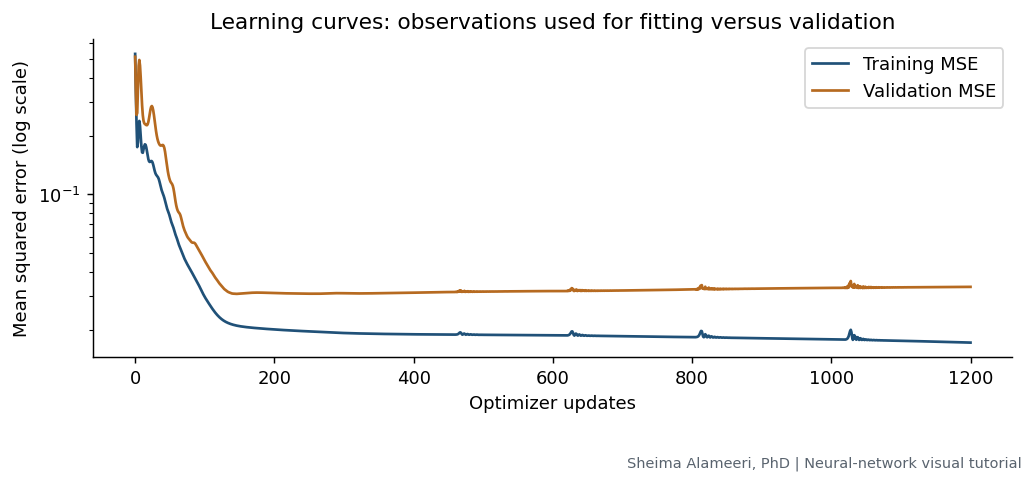

In [4]:
fig, ax = plt.subplots(figsize=(8, 3.7))
ax.plot(history['Epoch'], history['Training MSE'], color=BLUE, label='Training MSE')
ax.plot(history['Epoch'], history['Validation MSE'], color=ORANGE, label='Validation MSE')
ax.set(xlabel='Optimizer updates', ylabel='Mean squared error (log scale)', yscale='log',
       title='Learning curves: observations used for fitting versus validation')
ax.legend()
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_figure(fig, 'learning-curves.png')


## 4. Overfitting and a validation-selected checkpoint

For a separate illustration, we use only 24 noisy training observations and a larger **1 → 128 → 128 → 1** ReLU network. We predefine a budget of 5,000 updates, save the checkpoint with the lowest validation MSE, and compare it with the final checkpoint. This is retrospective checkpoint selection, equivalent to keeping the best observed validation checkpoint; the training run still completes its full budget.

After checkpoint selection, we generate an independent test set from a separate random stream. The test set is used once to evaluate these two checkpoints, never for gradient updates or choosing the best epoch. A single split illustrates the idea; it does not prove that larger networks or longer training always overfit.


         Checkpoint  Epoch  Training MSE  Validation MSE  Test MSE
Validation-selected    132        0.0406          0.1009    0.1037
              Final   5000        0.0042          0.1841    0.1613


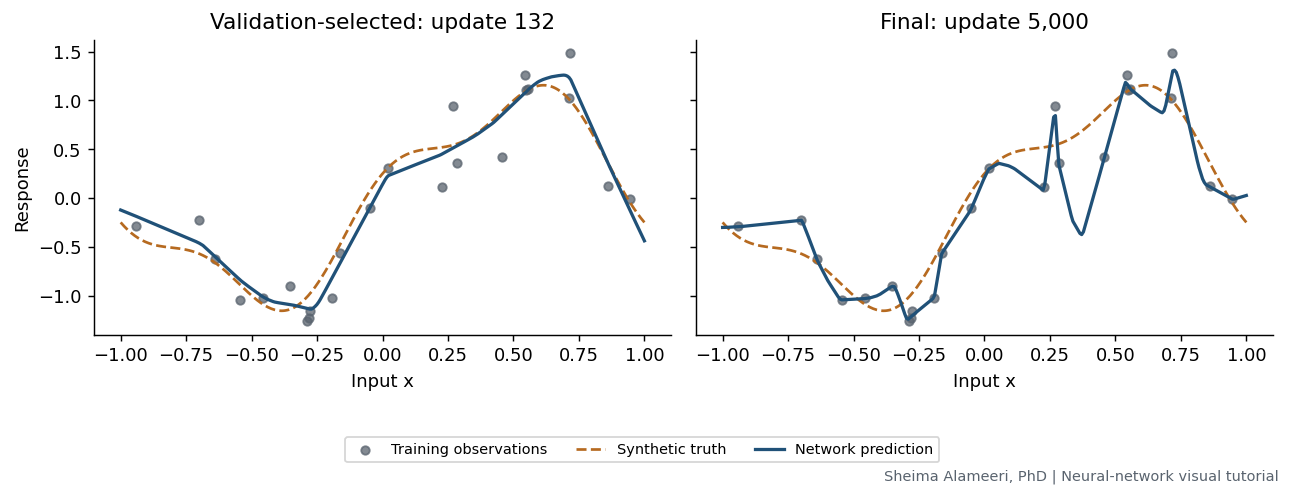

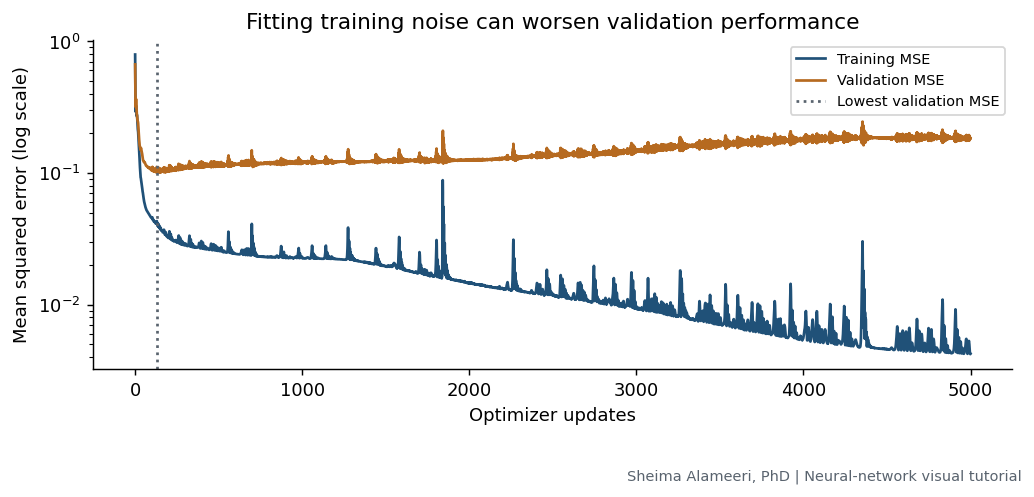

In [5]:
small_x, small_y, holdout_x, holdout_y = make_data(SEED+10, 24, 300, 0.30)
large_model = make_model(128, nn.ReLU, SEED+10)
overfit_history, selected_state, selected_epoch = train_model(
    large_model, small_x, small_y, holdout_x, holdout_y, epochs=5000, lr=0.005)
final_large_state = deepcopy(large_model.state_dict())
selected_model = make_model(128, nn.ReLU, SEED+11)
selected_model.load_state_dict(selected_state)
selected_valid_mse = np.mean((predict(selected_model, holdout_x)-holdout_y.numpy().ravel())**2)
np.testing.assert_allclose(selected_valid_mse, overfit_history['Validation MSE'].min(), rtol=1e-5)

test_rng = np.random.default_rng(SEED+100)
test_x = tensor(test_rng.uniform(-1, 1, 600))
test_y = tensor(true_function(test_x.numpy().ravel()) + test_rng.normal(0, 0.30, len(test_x)))
comparison = []
for label, fitted, epoch in [('Validation-selected', selected_model, selected_epoch),
                              ('Final', large_model, 5000)]:
    comparison.append({'Checkpoint':label, 'Epoch':epoch,
        'Training MSE':float(np.mean((predict(fitted, small_x)-small_y.numpy().ravel())**2)),
        'Validation MSE':float(np.mean((predict(fitted, holdout_x)-holdout_y.numpy().ravel())**2)),
        'Test MSE':float(np.mean((predict(fitted, test_x)-test_y.numpy().ravel())**2))})
metrics = pd.DataFrame(comparison)
assert np.isfinite(metrics.select_dtypes(include='number').to_numpy()).all()
overfit_history.to_csv(ASSETS/'overfitting-history.csv', index=False)
metrics.to_csv(ASSETS/'checkpoint-comparison.csv', index=False)
print(metrics.to_string(index=False, float_format=lambda v:f'{v:.4f}'))

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for ax, fitted, title in zip(axes, [selected_model, large_model],
    [f'Validation-selected: update {selected_epoch}', 'Final: update 5,000']):
    ax.scatter(small_x.numpy().ravel(), small_y.numpy().ravel(), color=GRAY, s=22,
               alpha=0.75, label='Training observations')
    ax.plot(xx, true_function(xx), '--', color=ORANGE, label='Synthetic truth')
    ax.plot(xx, predict(fitted, grid), color=BLUE, lw=1.8, label='Network prediction')
    ax.set(xlabel='Input x', title=title)
axes[0].set_ylabel('Response')
handles, labels=axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, fontsize=8, bbox_to_anchor=(0.5, 0.035))
fig.tight_layout(rect=(0, 0.15, 1, 1))
save_figure(fig, 'checkpoint-predictions.png')

fig, ax=plt.subplots(figsize=(8, 3.8))
ax.plot(overfit_history['Epoch'], overfit_history['Training MSE'], color=BLUE, label='Training MSE')
ax.plot(overfit_history['Epoch'], overfit_history['Validation MSE'], color=ORANGE, label='Validation MSE')
ax.axvline(selected_epoch, color=GRAY, ls=':', label='Lowest validation MSE')
ax.set(xlabel='Optimizer updates', ylabel='Mean squared error (log scale)', yscale='log',
       title='Fitting training noise can worsen validation performance')
ax.legend(fontsize=8)
fig.tight_layout(rect=(0, 0.08, 1, 1))
save_figure(fig, 'overfitting-curves.png')


Read the checkpoint table together with the curves. Lower training error can coexist with worse validation or test error. Validation-selected checkpoints can help, but validation itself is a finite sample and the best observed validation score is optimistic after searching many epochs. The independent test set provides a separate assessment for this example.

## 5. Check a gradient

Backpropagation applies the chain rule efficiently. As a small numerical check, compare PyTorch's automatic derivatives for a two-layer tanh network with finite-difference derivatives. This validates the differentiable computation used in the example; it is not a proof of successful optimization or generalization.


In [6]:
check_generator=torch.Generator().manual_seed(SEED+200)
check_x=torch.tensor([[-0.7],[0.2],[0.8]],dtype=torch.float64)
check_y=torch.tensor([[0.1],[-0.2],[0.7]],dtype=torch.float64)
parameters=tuple(torch.randn(shape,generator=check_generator,dtype=torch.float64,
                            requires_grad=True)
                 for shape in [(1,3),(3,),(3,1),(1,)])
def small_loss(w,b,v,c):
    prediction=torch.tanh(check_x@w+b)@v+c
    return ((prediction-check_y)**2).mean()
assert torch.autograd.gradcheck(small_loss,parameters,eps=1e-6,atol=1e-5,rtol=1e-3)
print('Finite-difference gradient check passed.')


Finite-difference gradient check passed.


## Takeaways and exercises

- Weights and biases define affine transformations; activations introduce nonlinearity.
- Training uses gradients to reduce a specified loss; successful fitting does not guarantee generalization.
- Validation supports model and checkpoint selection. Keep test data separate until final evaluation.
- The network curves here are point predictions, not confidence or predictive intervals.

Try changing the noise level, sample size, or hidden width. Rerun every cell. Compare training and validation behavior before looking at a fresh test set. Do not repeatedly use the same test set to guide choices.

**Limitations:** one-dimensional regression, synthetic data, one split per experiment, small fully connected networks, and fixed training settings. The notebook is an illustration, not a benchmark or a claim about all neural networks. CPU execution is deterministic in the recorded environment; results may differ across library versions or hardware.

## References and attribution

- Goodfellow, I., Bengio, Y., and Courville, A. (2016). *Deep Learning*. MIT Press. [Chapter 6: Deep Feedforward Networks](https://www.deeplearningbook.org/contents/mlp.html) and [Chapter 7: Regularization](https://www.deeplearningbook.org/contents/regularization.html).
- PyTorch. [Optimizing Model Parameters](https://docs.pytorch.org/tutorials/beginner/basics/optimization_tutorial.html).

These references describe standard concepts and software usage. The included experiments use fresh synthetic data; the figures are generated by the accompanying code. This is an educational presentation of established methods, not a claim to invent neural-network algorithms.

**Author and maintainer:** Sheima Alameeri, PhD  
**Contact:** [sheima.alameeri@gmail.com](mailto:sheima.alameeri@gmail.com)
